In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("paper_style.mplstyle")
from paper_palette import (
    NATIVE_APY_COLOR, BORROW_COST_COLOR,
    SPREAD_POS_COLOR, SPREAD_NEG_COLOR,
)


In [2]:

NATIVE_APY = { # 14 Jul
    "syrupUSDC": 4.86,
    "sUSDe":     3.96,
    "sUSDS":     3.60,
}
# Morpho Colleteral / Loan / Borrow Rate at 14 Jul checked via morpho graphql
TARGET_PAIRS = [
    ("syrupUSDC", "PYUSD", 4.43),
    ("sUSDS", "USDT", 2.57),
    ("sUSDe", "PYUSD", 3.2),
    ("syrupUSDC", "AUSD", 3.46),
    ("syrupUSDC", "RLUSD", 4.5),
    ("sUSDe", "USDtb", 4.38),
    ("sUSDS", "AUSD", 3.62),
    ("sUSDe", "msUSD", 5.43), # avg of that day was spiking quite a lot
]

AAVE_PAIRS = [
    ("sUSDe", "USDT", 3.7),  # $985M collateral, largest market
    ("sUSDe", "USDC", 4.25),  # $780M
    ("sUSDe", "USDe", 2.1),  # $540M
    ("sUSDe", "GHO", 3.8),  # $180M
    ("sUSDe", "USDS", 5.6),  # $175M
    ("sUSDe", "USDtb", 4),  # $115M
    ("sUSDe", "DAI", 4.6),  # $40M
]

In [3]:
morpho_files = {
    "sUSDe":     "../from_dune/borrowers/morpho_borrowers_susde.csv",
    "sUSDS":     "../from_dune/borrowers/morpho_borrowers_susds.csv",
    "syrupUSDC": "../from_dune/borrowers/morpho_borrowers_syrup.csv",
}
morpho_dfs = {name: pd.read_csv(path).assign(asset=name) for name, path in morpho_files.items()}
morpho_borrowers = pd.concat(morpho_dfs.values(), ignore_index=True)

aave_raw = pd.read_csv("../from_dune/borrowers/aave_borrowers_susde.csv")

print(f"Morpho: {len(morpho_borrowers)} positions")
print(f"Aave: {len(aave_raw)} rows")

Morpho: 350 positions
Aave: 2356 rows


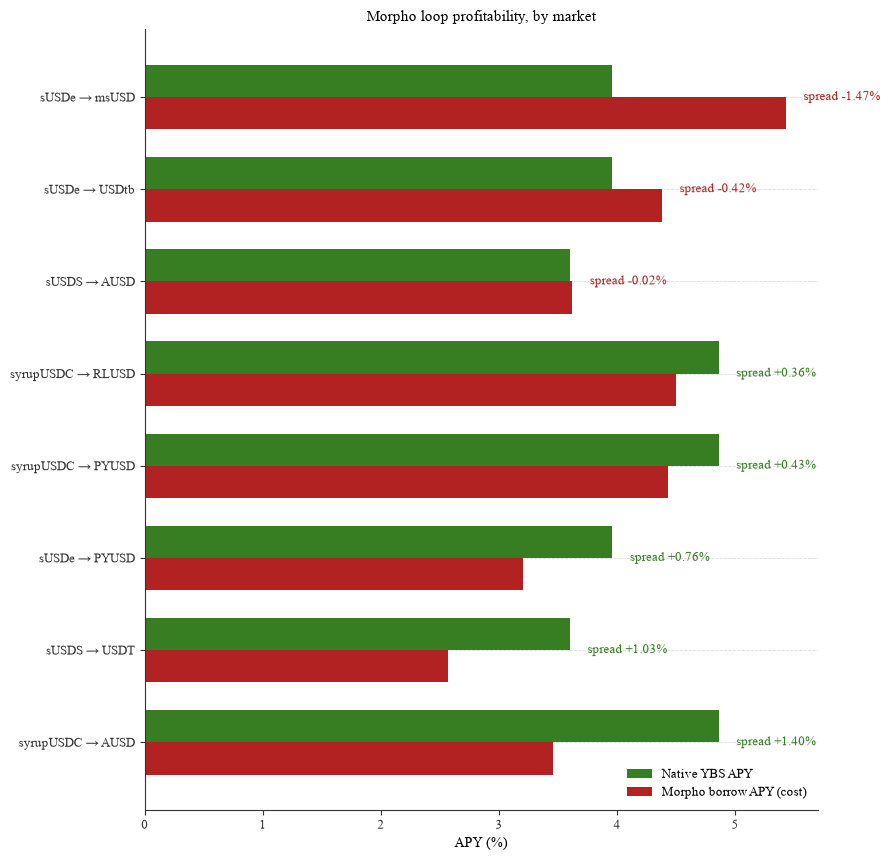

In [4]:
# Loop profitability in Morpho markets, same style as the Aave chart
labels = [f"{collat} → {loan}" for collat, loan, _ in TARGET_PAIRS]
native_apys = [NATIVE_APY[collat] for collat, loan, rate in TARGET_PAIRS]
borrow_apys = [rate for collat, loan, rate in TARGET_PAIRS]
spreads = [n - b for n, b in zip(native_apys, borrow_apys)]

# sort by spread so the most profitable loops sit at the top, matching typical read order
order = np.argsort(spreads)[::-1]
labels = [labels[i] for i in order]
native_apys = [native_apys[i] for i in order]
borrow_apys = [borrow_apys[i] for i in order]
spreads = [spreads[i] for i in order]

y = np.arange(len(labels))
bar_height = 0.35

fig, ax = plt.subplots(figsize=(9, 0.9 * len(labels) + 1.5))

ax.barh(y + bar_height / 2, native_apys, height=bar_height, color=NATIVE_APY_COLOR, label="Native YBS APY")
ax.barh(y - bar_height / 2, borrow_apys, height=bar_height, color=BORROW_COST_COLOR, label="Morpho borrow APY (cost)")

for i, spread in enumerate(spreads):
    color = SPREAD_POS_COLOR if spread >= 0 else SPREAD_NEG_COLOR
    sign = "+" if spread >= 0 else ""
    max_bar = max(native_apys[i], borrow_apys[i])
    ax.text(max_bar + 0.15, y[i], f"spread {sign}{spread:.2f}%", va="center", fontsize=9, color=color)

ax.set_yticks(y)
ax.set_yticklabels(labels)
ax.set_xlabel("APY (%)")
ax.set_title("Morpho loop profitability, by market")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("../output/morpho_loop_profitability.png", dpi=300, bbox_inches="tight")
plt.show()

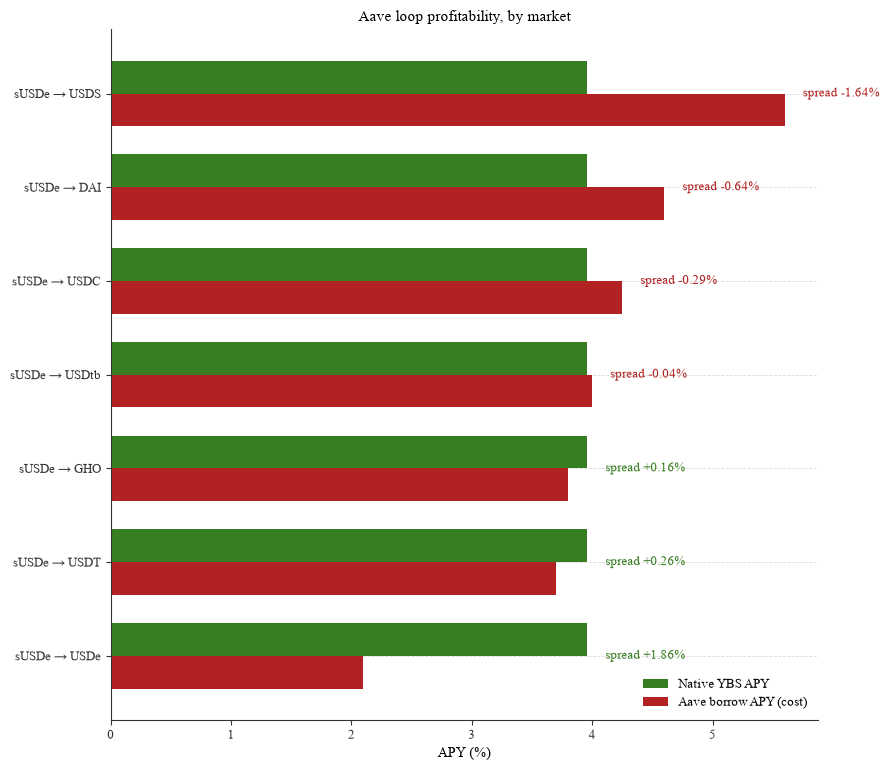

In [5]:
# Loop profitability in Aave markets, same style as the Morpho chart
labels = [f"{collat} → {loan}" for collat, loan, _ in AAVE_PAIRS]
native_apys = [NATIVE_APY[collat] for collat, loan, rate in AAVE_PAIRS]
borrow_apys = [rate for collat, loan, rate in AAVE_PAIRS]
spreads = [n - b for n, b in zip(native_apys, borrow_apys)]

# sort by spread so the most profitable loops sit at the top
order = np.argsort(spreads)[::-1]
labels = [labels[i] for i in order]
native_apys = [native_apys[i] for i in order]
borrow_apys = [borrow_apys[i] for i in order]
spreads = [spreads[i] for i in order]

y = np.arange(len(labels))
bar_height = 0.35

fig, ax = plt.subplots(figsize=(9, 0.9 * len(labels) + 1.5))

ax.barh(y + bar_height / 2, native_apys, height=bar_height, color=NATIVE_APY_COLOR, label="Native YBS APY")
ax.barh(y - bar_height / 2, borrow_apys, height=bar_height, color=BORROW_COST_COLOR, label="Aave borrow APY (cost)")

for i, spread in enumerate(spreads):
    color = SPREAD_POS_COLOR if spread >= 0 else SPREAD_NEG_COLOR
    sign = "+" if spread >= 0 else ""
    max_bar = max(native_apys[i], borrow_apys[i])
    ax.text(max_bar + 0.15, y[i], f"spread {sign}{spread:.2f}%", va="center", fontsize=9, color=color)

ax.set_yticks(y)
ax.set_yticklabels(labels)
ax.set_xlabel("APY (%)")
ax.set_title("Aave loop profitability, by market")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("../output/aave_loop_profitability.png", dpi=300, bbox_inches="tight")
plt.show()